In [17]:
import numpy as np 
import pandas as pd 

In [18]:
data = pd.read_csv('twin_data/dataset/throws_fake.csv')

In [19]:
swing_time = data['swing_time'].to_numpy()
release_time = data['release_time'].to_numpy()
landing = data['landing_x'].to_numpy()

In [20]:
import matplotlib.pyplot as plt 

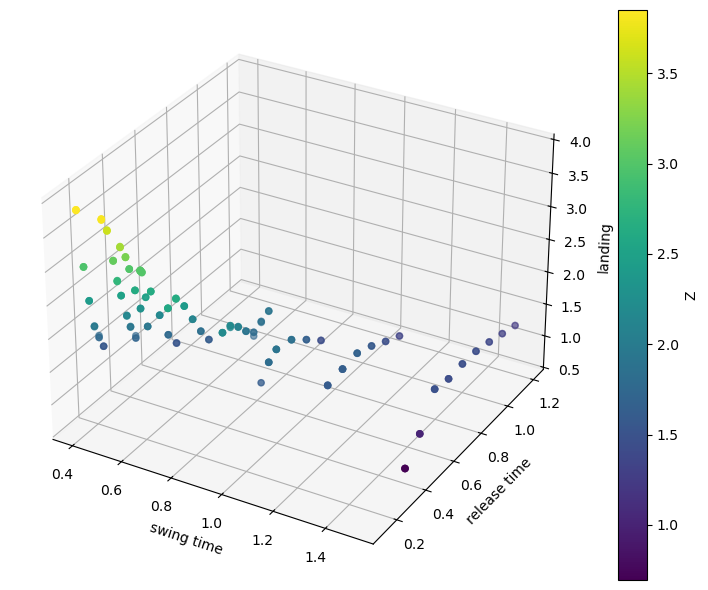

In [24]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

sc = ax.scatter(swing_time, release_time, landing, c=landing, cmap='viridis', s=20)

ax.set_xlabel('swing time')
ax.set_ylabel('release time')
ax.set_zlabel('landing')

plt.colorbar(sc, ax=ax, label='Z')
plt.tight_layout()
plt.show()

In [6]:
import gpytorch 

In [7]:

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    RBF, ConstantKernel, WhiteKernel
)
from sklearn.preprocessing import StandardScaler
from scipy.optimize import differential_evolution, minimize


In [8]:
gp_input = np.array([swing_time, release_time]).T 

In [9]:
x_scaler = StandardScaler()
z_scaler = StandardScaler()

x_scaled = x_scaler.fit_transform(gp_input)
z_scaled = z_scaler.fit_transform(landing.reshape(-1, 1)).ravel()

In [10]:
kernel = (
    ConstantKernel(1.0, (1e-3, 1e3))
    * RBF(length_scale=[1.0, 1.0],
          length_scale_bounds=(1e-2, 1e2))
    + WhiteKernel(noise_level=0.1,
                  noise_level_bounds=(1e-5, 1e1))
)

gp = GaussianProcessRegressor(
    kernel=kernel,
    n_restarts_optimizer=20,
    normalize_y=False
)

gp.fit(x_scaled, z_scaled)

print("Optimized kernel:", gp.kernel_)
print("Log marginal likelihood:", gp.log_marginal_likelihood_value_)

Optimized kernel: 0.905**2 * RBF(length_scale=[0.353, 0.168]) + WhiteKernel(noise_level=0.000106)
Log marginal likelihood: 311.2153326845363


In [11]:

lambda_unc = 1.0
sigma_max = 0.05

bounds = [
    (0.4, 1.5),
    (0.1, 1.0)
]

def predict_gp(xy):
    X_query = x_scaler.transform(
        np.array(xy).reshape(1, -1)
    )

    mu, std = gp.predict(X_query, return_std=True)

    mu = z_scaler.inverse_transform(
        mu.reshape(-1, 1)
    )[0, 0]

    std = std[0] * z_scaler.scale_[0]

    return mu, std


def objective_constrained(xy, z_des):
    mu, std = predict_gp(xy)
    return (mu - z_des)**2


def uncertainty_constraint(xy):
    mu, std = predict_gp(xy)
    return sigma_max - std

In [12]:
def compute_trajectoies(z_des):
    result = minimize(
        objective_constrained,
        x0=[0.5, 0.23],
        args=(z_des),
        bounds=bounds,
        constraints=[
            {'type': 'ineq', 'fun': uncertainty_constraint}
        ],
        method='SLSQP'
    )

    if result.success:
        x_opt, y_opt = result.x
        print("Optimal solution:", 'swing time', x_opt, 'release time', y_opt)
        return x_opt, y_opt
    else:
        print("Optimization failed:", result.message)


In [13]:
swing_time, release_time = compute_trajectoies(3.0)

Optimal solution: swing time 0.5941682222803794 release time 0.20305728309389526
